# 🔥 Lesson 05 · PyTorch Fundamentals

*“PyTorch is the NumPy you already know: plus autograd, plus a GPU, plus a box of ready-made layers.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~100 min | 🟡 Intermediate | Day 4–5 | Lessons 02–04 (you built all of this by hand!) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Create and manipulate **tensors** and move between NumPy and PyTorch
- Use **autograd** and confirm it matches the gradients you derived by hand
- Build models with **`nn.Module`**, `nn.Linear` and `nn.Sequential`; count parameters
- Load data with **`Dataset` / `DataLoader`** (mini-batches!)
- Write the canonical **5-step training loop** from memory and train a classifier and a regressor
- Avoid the classic bugs (missing `zero_grad`, softmax before `CrossEntropyLoss`, wrong dtypes)
- Save and load a trained model

## 🗺 Roadmap
1. Why a framework?
2. Tensors
3. Autograd
4. `nn.Module`
5. Losses & optimisers
6. `Dataset` & `DataLoader`
7. The training loop
8. A regression example
9. Saving models
10. Debugging checklist
11. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch
import torch.nn as nn
import torch.nn.functional as F
print('PyTorch', torch.__version__)
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

PyTorch 2.15.0+cu132


---
## 🧰 1. Why a framework?

In Lesson 04 you wrote forward passes, backprop, and gradient descent by hand. It worked, but imagine doing it for a 50-layer
network with convolutions and attention. A framework gives you three superpowers:

| Superpower | What it replaces |
|:--|:--|
| **Autograd** | Hand-derived backprop: gradients for *any* composition of operations, automatically |
| **Fast tensors (CPU / GPU)** | Slow NumPy loops; one line moves everything to a GPU |
| **Building blocks** (`nn.Linear`, `nn.Conv2d`, `nn.LSTM`, optimisers, data loaders) | Rewriting the same code for every project |

**Why PyTorch?** It feels like ordinary Python (you can `print` a tensor mid-model and use `if`/`for` freely), which makes it the
dominant framework in research and increasingly in industry. Everything you learn transfers to TensorFlow/Keras (Lesson 15).

---
## 🧮 2. Tensors

A **tensor** is an n-dimensional array; NumPy's `ndarray` with extra abilities. Scalars are 0-D, vectors 1-D, matrices 2-D, batches of images 4-D `(N, C, H, W)`.

In [2]:
a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
print("shape:", a.shape, "| dtype:", a.dtype, "| device:", a.device)
print("zeros:", torch.zeros(2, 2).tolist(), "| random normal:", torch.randn(2, 2).shape)
print("matmul:", (a @ a.T).tolist())
print("broadcasting (a - column means):", (a - a.mean(dim=0)).tolist())
print("slicing a[:, 1]:", a[:, 1], "| boolean mask a[a>3]:", a[a > 3])

shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu
zeros: [[0.0, 0.0], [0.0, 0.0]] | random normal: torch.Size([2, 2])
matmul: [[14.0, 32.0], [32.0, 77.0]]
broadcasting (a - column means): [[-1.5, -1.5, -1.5], [1.5, 1.5, 1.5]]
slicing a[:, 1]: tensor([2., 5.]) | boolean mask a[a>3]: tensor([4., 5., 6.])


### Shape-shifting (you'll do this constantly)
| Operation | Example | Result |
|:--|:--|:--|
| `reshape` / `view` | `x.reshape(32, -1)` | Same data, new shape (`-1` = infer) |
| `unsqueeze(d)` / `squeeze()` | `x.unsqueeze(0)` | Add / remove a size-1 axis |
| `permute` | `img.permute(2, 0, 1)` | Reorder axes: `(H,W,C) → (C,H,W)` |
| `flatten(start_dim)` | `x.flatten(1)` | Collapse everything after the batch axis |

In [3]:
batch = torch.randn(8, 1, 28, 28)                 # 8 grayscale images: (N, C, H, W)
print("flatten for an MLP :", batch.flatten(1).shape)
leaf = torch.rand(48, 48, 3)                      # NumPy/PIL images are (H, W, C) ...
print("PyTorch wants (C,H,W):", leaf.permute(2, 0, 1).shape)
print("add batch axis      :", leaf.permute(2, 0, 1).unsqueeze(0).shape)

flatten for an MLP : torch.Size([8, 784])
PyTorch wants (C,H,W): torch.Size([3, 48, 48])
add batch axis      : torch.Size([1, 3, 48, 48])


> ⚠️ **Watch out**: **Dtypes bite.** Features should be `float32` (`torch.float32`); **class labels for `CrossEntropyLoss` must be `int64`** (`torch.long`). A float label tensor or a double-precision input gives errors like *"expected scalar type Float but found Double"*. Cast with `.float()` / `.long()`.

In [4]:
# NumPy ↔ PyTorch bridge. WARNING: from_numpy SHARES memory with the array!
arr = np.ones(3)
t = torch.from_numpy(arr)
arr[0] = 99
print("changing the numpy array changed the tensor too:", t)
print("back to numpy:", t.numpy(), "| independent copy:", torch.tensor(arr).clone()[:2])
print("GPU available?", torch.cuda.is_available(), "| our device:", dl.get_device())

changing the numpy array changed the tensor too: tensor([99.,  1.,  1.], dtype=torch.float64)
back to numpy: [99.  1.  1.] | independent copy: tensor([99.,  1.], dtype=torch.float64)
GPU available? False | our device: cpu


---
## 🔄 3. Autograd: gradients for free

Tell PyTorch to *track* a tensor with `requires_grad=True`; every operation builds a graph exactly like our `Value` class in Lesson 04; `.backward()` fills each tensor's `.grad`. Let's rerun the neuron from last lesson (expected: `dL/dw = −0.1081`, `dL/db = −0.0721`):

In [5]:
x, y = torch.tensor(1.5), torch.tensor(1.0)
w = torch.tensor(0.8, requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)

a = torch.sigmoid(w * x + b)
loss = (a - y) ** 2
loss.backward()
print(f"loss = {loss.item():.4f}")
print(f"dL/dw = {w.grad.item():.4f}   dL/db = {b.grad.item():.4f}   ← matches our hand calculation AND our Value engine")

loss = 0.0459
dL/dw = -0.1081   dL/db = -0.0721   ← matches our hand calculation AND our Value engine


**Gradients accumulate**: call `backward()` twice and they add. That's why every loop zeroes them. See it happen:

In [6]:
w = torch.tensor(2.0, requires_grad=True)
for i in range(3):
    (w ** 2).backward()                  # d(w²)/dw = 2w = 4
    print(f"after backward #{i + 1}: w.grad = {w.grad.item()}")
w.grad.zero_()                           # this is what optimizer.zero_grad() does for every parameter
print("after zeroing:", w.grad.item())

with torch.no_grad():                    # inference mode: no graph, saves memory & time
    print("inside no_grad, requires_grad of result:", (w * 3).requires_grad)

after backward #1: w.grad = 4.0
after backward #2: w.grad = 8.0
after backward #3: w.grad = 12.0
after zeroing: 0.0
inside no_grad, requires_grad of result: False


> 🛠 **Pro tip**: Use `with torch.no_grad():` (or `model.eval()` plus `no_grad`) whenever you only want predictions: evaluation, inference, plotting. And `.item()` converts a 1-element tensor to a Python float (useful for logging; avoids hoarding the graph in memory).

---
## 🏗 4. `nn.Module`: models as Lego

`nn.Linear(n_in, n_out)` is Lesson 02's dense layer: it owns a weight matrix and a bias and computes `x @ Wᵀ + b`. (PyTorch stores `W` as `(n_out, n_in)`.) A **model** is a class that subclasses `nn.Module`, creates layers in `__init__`, and defines the forward pass in `forward`.

In [7]:
lin = nn.Linear(784, 128)
print("weight:", tuple(lin.weight.shape), "(out, in)   bias:", tuple(lin.bias.shape))

# Way 1: Sequential: great for simple stacks
seq = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

# Way 2: a custom class: full control (needed for branching, skip-connections, attention, ...)
class DigitNet(nn.Module):
    def __init__(self, hidden=(128, 64), n_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(784, hidden[0])
        self.fc2 = nn.Linear(hidden[0], hidden[1])
        self.out = nn.Linear(hidden[1], n_classes)
    def forward(self, x):
        x = x.flatten(1)                    # (N,1,28,28) or (N,784) → (N,784)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)                  # raw logits: NO softmax here!

net = DigitNet()
print(net)
print("parameters:", dl.count_params(net), " (our hand count in Lesson 02: 109,386)")
print("output shape for a batch of 5:", net(torch.randn(5, 784)).shape)
for name, p in list(net.named_parameters())[:4]:
    print(f"  {name:12s} {tuple(p.shape)}")

weight: (128, 784) (out, in)   bias: (128,)
DigitNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=10, bias=True)
)
parameters: 109386  (our hand count in Lesson 02: 109,386)
output shape for a batch of 5: torch.Size([5, 10])
  fc1.weight   (128, 784)
  fc1.bias     (128,)
  fc2.weight   (64, 128)
  fc2.bias     (64,)


> 📝 **Note**: `net(x)` calls `net.forward(x)` (never call `forward` directly; `__call__` also runs hooks). Registering layers as attributes (`self.fc1 = ...`) is what lets `net.parameters()` find every weight to hand to the optimiser.

---
## 🎯 5. Losses & optimisers

| Task | Loss | What it expects |
|:--|:--|:--|
| Multi-class | `nn.CrossEntropyLoss()` | **raw logits** `(N, k)` + **integer labels** `(N,)`: it applies log-softmax internally |
| Binary | `nn.BCEWithLogitsLoss()` | raw logit `(N,)` + float labels in {0,1}: applies sigmoid internally |
| Regression | `nn.MSELoss()` / `nn.L1Loss()` / `nn.HuberLoss()` | predictions + float targets, same shape |

**Optimisers** (`torch.optim.SGD`, `Adam`, …) hold the parameters and know how to update them. Lesson 06 explains each; for now `Adam(lr=1e-3)` is a superb default.

#### The most common bug in all of deep learning: softmax before `CrossEntropyLoss`

In [8]:
logits = torch.tensor([[10.0, 0.0, 0.0]])        # the model is VERY confident in class 0: and right
target = torch.tensor([0])
ce = nn.CrossEntropyLoss()
print("correct: CE(logits)          =", f"{ce(logits, target).item():.6f}   (≈ 0; as it should be)")
print("BUG    : CE(softmax(logits)) =", f"{ce(torch.softmax(logits, 1), target).item():.6f}   ← loss can never get near 0; gradients are squashed")

correct: CE(logits)          = 0.000091   (≈ 0; as it should be)
BUG    : CE(softmax(logits)) = 0.551502   ← loss can never get near 0; gradients are squashed


---
## 📦 6. `Dataset` & `DataLoader`: serving mini-batches

We don't feed the whole dataset at once (memory!) nor one example at a time (slow, noisy). We use **mini-batches**. A `DataLoader` wraps a dataset, shuffles it every epoch, and hands you batches.

In [9]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=600, noise=0.2, random_state=0)
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
to_t = lambda a, dtype: torch.tensor(a, dtype=dtype)
train_ds = TensorDataset(to_t(Xtr, torch.float32), to_t(ytr, torch.long))
val_ds   = TensorDataset(to_t(Xva, torch.float32), to_t(yva, torch.long))
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)       # shuffle=True only for training!
val_dl   = DataLoader(val_ds, batch_size=128)

xb, yb = next(iter(train_dl))
print("one batch:", xb.shape, xb.dtype, "| labels:", yb.shape, yb.dtype)
print("batches per epoch:", len(train_dl), "(450 samples / 32 per batch → 15, the last one is smaller)")

one batch: torch.Size([32, 2]) torch.float32 | labels: torch.Size([32]) torch.int64
batches per epoch: 15 (450 samples / 32 per batch → 15, the last one is smaller)


---
## 🔁 7. The training loop: the 5 steps you'll write 1000 times

```
for each epoch:
    for each mini-batch (xb, yb):
        1. pred  = model(xb)                # forward pass
        2. loss  = loss_fn(pred, yb)        # how wrong are we?
        3. optimizer.zero_grad()            # clear old gradients
        4. loss.backward()                  # backprop: fill every .grad
        5. optimizer.step()                 # nudge every parameter
    evaluate on validation data (model.eval(), no_grad)
```
> 🎓 *Say it aloud:* **forward, loss, zero, backward, step.** Everything else is decoration.

Let's classify the two interleaved moons.

epoch 10 | train loss 0.0871 | val acc 0.927
epoch 20 | train loss 0.0483 | val acc 0.953


epoch 30 | train loss 0.0617 | val acc 0.947
epoch 40 | train loss 0.0685 | val acc 0.967


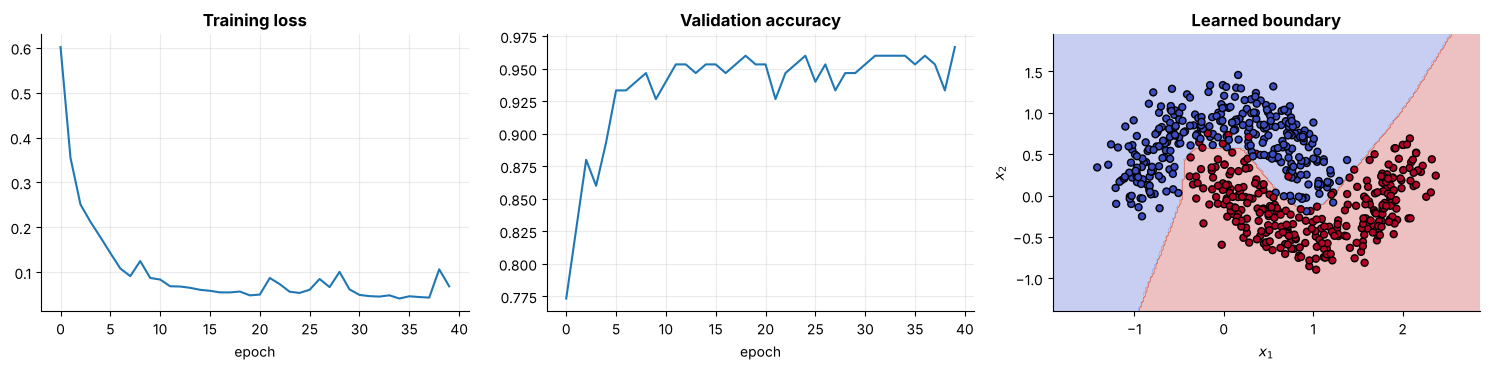

In [10]:
model = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 2))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

train_losses, val_accs = [], []
for epoch in range(1, 41):
    model.train()                                           # (matters for dropout/batch-norm later)
    total = 0.0
    for xb, yb in train_dl:
        pred = model(xb)                                    # 1. forward
        loss = loss_fn(pred, yb)                            # 2. loss
        optimizer.zero_grad()                               # 3. zero
        loss.backward()                                     # 4. backward
        optimizer.step()                                    # 5. step
        total += loss.item() * len(xb)
    train_losses.append(total / len(train_ds))

    model.eval()
    with torch.no_grad():
        correct = sum((model(xb).argmax(1) == yb).sum().item() for xb, yb in val_dl)
    val_accs.append(correct / len(val_ds))
    if epoch % 10 == 0:
        print(f"epoch {epoch:2d} | train loss {train_losses[-1]:.4f} | val acc {val_accs[-1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(train_losses); ax[0].set(title="Training loss", xlabel="epoch")
ax[1].plot(val_accs); ax[1].set(title="Validation accuracy", xlabel="epoch")
predict = lambda pts: model(torch.tensor(pts, dtype=torch.float32)).argmax(1).detach().numpy()
dl.plot_decision_boundary(predict, X, y, ax=ax[2], title="Learned boundary")
plt.tight_layout(); plt.show()

> 💡 **Big idea**: `dl.fit(...)` in `utils/dlcourse.py` is this exact loop with extras (history, schedulers, early stopping). Open the file and read it: you'll recognise every line. From Lesson 06 on we use it so our notebooks stay readable.

---
## 📈 8. A regression example: learning a curve

Everything is identical except: the output layer has **1 neuron with no activation**, and the loss is `MSELoss`. We'll fit a noisy sine wave: something no straight line can do.

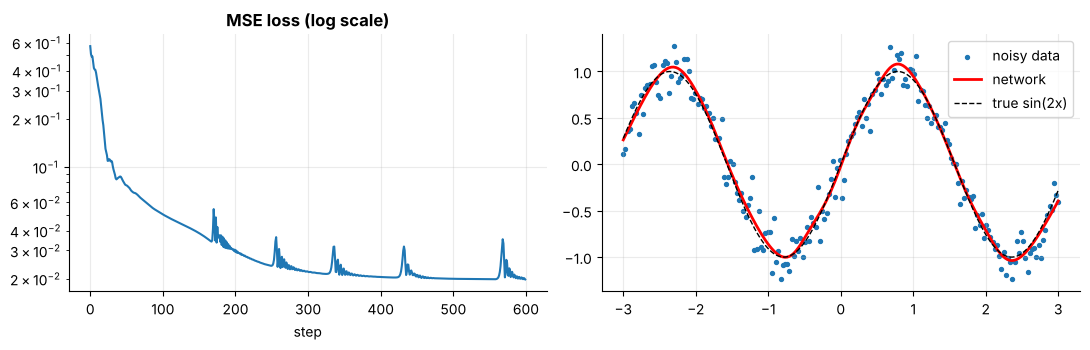

In [11]:
torch.manual_seed(0)
xs = torch.linspace(-3, 3, 200).unsqueeze(1)                 # (200, 1)  ← regression inputs need the feature axis
ys = torch.sin(2 * xs) + 0.15 * torch.randn_like(xs)

reg = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))
opt = torch.optim.Adam(reg.parameters(), lr=0.01)
mse = nn.MSELoss()
losses = []
for step in range(600):                                      # full-batch training: the "batch" is all 200 points
    loss = mse(reg(xs), ys)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(losses); ax[0].set_yscale("log"); ax[0].set(title="MSE loss (log scale)", xlabel="step")
ax[1].scatter(xs, ys, s=8, label="noisy data"); ax[1].plot(xs, reg(xs).detach(), "r", lw=2, label="network"); ax[1].plot(xs, torch.sin(2 * xs), "k--", lw=1, label="true sin(2x)"); ax[1].legend()
plt.tight_layout(); plt.show()

---
## 💾 9. Saving and loading

In [12]:
import tempfile, os
path = os.path.join(tempfile.gettempdir(), "moons_model.pt")
torch.save(model.state_dict(), path)                          # save the WEIGHTS (recommended), not the whole object

fresh = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 2))   # same architecture
fresh.load_state_dict(torch.load(path))
fresh.eval()
same = torch.allclose(model(xb), fresh(xb))
print("restored model gives identical predictions:", same)

restored model gives identical predictions: True


> 🇰🇪 **In the field**: A trained model is just a file of numbers. Saving `state_dict()`s is how you'd ship a crop-disease classifier inside a phone app; Lesson 15 touches on exporting to mobile-friendly formats.

---
## 🩺 10. Debugging checklist (print this!)

| Symptom | Likely cause | Fix |
|:--|:--|:--|
| `RuntimeError: mat1 and mat2 shapes cannot be multiplied` | Wrong `in_features` / forgot to flatten | Print `x.shape` before each layer |
| `expected scalar type Long but found Float` | Labels not `int64` | `y = y.long()` |
| `expected Float but found Double` | NumPy defaults to float64 | `x = x.float()` |
| Loss doesn't decrease | LR too low/high; forgot `optimizer.step()`; data not normalised | Overfit **one small batch** first: if it can't memorise 10 examples, there's a bug |
| Loss stuck near `ln(k)` | Network not learning (dead ReLUs, LR too small, labels shuffled vs inputs) | Check LR, data pipeline |
| Loss `nan` | LR too high; `log(0)`; exploding values | Lower LR, clip gradients, check inputs |
| Loss never gets near 0 on easy data | Softmax before `CrossEntropyLoss` | Remove the softmax from the model |
| Train acc ↑, val acc ↓ | Overfitting | Lesson 14 |
| Val results differ run to run | Forgot `model.eval()` (dropout/batch-norm) | Call `model.eval()` + `torch.no_grad()` |
| Gradients explode over several steps | Forgot `zero_grad()` | Add it before `backward()` |

> 🛠 **Karpathy's golden trick:** *before training on the full dataset, try to overfit a single batch of ~10 examples to ~100 % accuracy.* If you can't, your pipeline is broken: fix that before anything else.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 5.1: Tensor gymnastics  &nbsp; `⭐`

Write `prep(images, labels)` for a batch of MNIST-style images: `images` is a float tensor `(N, 28, 28)` with values in [0, 1].
Return `(x, counts)` where `x` is the images **flattened to `(N, 784)` and standardised** with mean 0.1307 and std 0.3081,
and `counts` is a tensor of length 10 with the number of examples per class (`torch.bincount` with `minlength=10`).

<details><summary>💡 Hint 1</summary>

`images.flatten(1)` or `images.reshape(len(images), -1)`.

</details>

<details><summary>💡 Hint 2</summary>

Standardise: `(x - 0.1307) / 0.3081`.

</details>

<details><summary>💡 Hint 3</summary>

`torch.bincount(labels, minlength=10)`.

</details>


In [ ]:
def prep(images, labels):
    pass   # return x, counts

In [ ]:
# ▶ self-check (run after you've written your answer)
imgs = torch.rand(20, 28, 28); labs = torch.tensor([0, 1, 1, 3, 3, 3] + [9] * 14)
out = prep(imgs, labs)
ok = out is not None
dl.check("x has shape (20, 784)", ok and out[0].shape == (20, 784))
dl.check("x is standardised correctly", ok and torch.allclose(out[0][0, 0], (imgs[0, 0, 0] - 0.1307) / 0.3081))
dl.check("class counts correct", ok and out[1].tolist() == [1, 2, 0, 3, 0, 0, 0, 0, 0, 14])

---
### 🧩 Problem 5.2: Autograd on your own function  &nbsp; `⭐⭐`

Write `grad_of(f, x0)` that takes a function `f` (scalar-valued, built from torch operations) and a Python list `x0`,
and returns the **gradient of `f` at `x0` as a list of floats**, computed with autograd.
Then verify it by hand for $f(x)=\sum_i x_i^2\sin(x_i)$, whose derivative is $2x\sin x + x^2\cos x$.

<details><summary>💡 Hint 1</summary>

`x = torch.tensor(x0, requires_grad=True)`

</details>

<details><summary>💡 Hint 2</summary>

`out = f(x); out.backward()`: then read `x.grad`.

</details>

<details><summary>💡 Hint 3</summary>

`x.grad.tolist()` converts to a list.

</details>


In [ ]:
def grad_of(f, x0):
    pass   # return a list of floats

In [ ]:
# ▶ self-check (run after you've written your answer)
f = lambda x: (x ** 2 * torch.sin(x)).sum()
pts = [0.5, 1.0, 2.0]
g = grad_of(f, pts)
truth = [2 * p * np.sin(p) + p ** 2 * np.cos(p) for p in pts]
dl.check("autograd gradient matches calculus", g is not None and np.allclose(g, truth, atol=1e-5))

---
### 🧩 Problem 5.3: Build an MLP factory  &nbsp; `⭐⭐`

Write `make_mlp(sizes)` returning an `nn.Sequential` with `nn.Linear` layers for consecutive sizes and a `nn.ReLU()` **between** layers
(not after the last one). e.g. `make_mlp([784, 128, 10])` → Linear(784,128), ReLU, Linear(128,10).

<details><summary>💡 Hint 1</summary>

Build a Python list of layers in a loop over `zip(sizes[:-1], sizes[1:])`.

</details>

<details><summary>💡 Hint 2</summary>

Add `nn.ReLU()` only if it's not the last pair.

</details>

<details><summary>💡 Hint 3</summary>

`nn.Sequential(*layers)` unpacks the list.

</details>


In [ ]:
def make_mlp(sizes):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
m = make_mlp([784, 128, 64, 10])
ok = m is not None
dl.check("109,386 parameters (as counted in Lesson 02)", ok and dl.count_params(m) == 109386)
dl.check("output shape (4, 10)", ok and m(torch.randn(4, 784)).shape == (4, 10))
dl.check("no activation after the final layer", ok and isinstance(list(m)[-1], nn.Linear))
dl.check("exactly 2 ReLUs", ok and sum(isinstance(l, nn.ReLU) for l in m) == 2)

---
### 🧩 Problem 5.4: Train a line  &nbsp; `⭐⭐`

Write `fit_line(x, y, epochs=300, lr=0.1)` that trains `nn.Linear(1, 1)` with SGD and MSE using the five-step loop (full batch),
and returns the learned `(w, b)` as Python floats. Data: $y=3x+2+\text{noise}$; you should recover roughly $w≈3,\ b≈2$.

<details><summary>💡 Hint 1</summary>

`model = nn.Linear(1, 1)`; `opt = torch.optim.SGD(model.parameters(), lr=lr)`

</details>

<details><summary>💡 Hint 2</summary>

`x` and `y` are shaped `(N, 1)`.

</details>

<details><summary>💡 Hint 3</summary>

After training: `model.weight.item()` and `model.bias.item()`.

</details>


In [ ]:
def fit_line(x, y, epochs=300, lr=0.1):
    pass   # return w, b

In [ ]:
# ▶ self-check (run after you've written your answer)
g = torch.Generator().manual_seed(0)
x = torch.rand(100, 1, generator=g) * 4 - 2
y = 3 * x + 2 + 0.1 * torch.randn(100, 1, generator=g)
res = fit_line(x, y)
dl.check("learned w ≈ 3 and b ≈ 2", res is not None and abs(res[0] - 3) < 0.15 and abs(res[1] - 2) < 0.15, "did you call zero_grad, backward and step?")

---
### 🧩 Problem 5.5: Hunt the two bugs  &nbsp; `⭐⭐`

This `train_step` is supposed to perform one correct update, but it contains **two classic bugs** (both discussed above).
Find and fix them. The self-check compares two consecutive steps with a reference implementation.

<details><summary>💡 Hint 1</summary>

Look at what is passed to the loss function. What does `CrossEntropyLoss` expect?

</details>

<details><summary>💡 Hint 2</summary>

What happens to `.grad` between step 1 and step 2?

</details>

<details><summary>💡 Hint 3</summary>

Bug 1: remove `torch.softmax(...)`. Bug 2: add `optimizer.zero_grad()` before `loss.backward()`.

</details>


In [ ]:
def train_step(model, loss_fn, optimizer, xb, yb):
    out = torch.softmax(model(xb), dim=1)     # 🐛
    loss = loss_fn(out, yb)
    loss.backward()                           # 🐛 (something is missing before this)
    optimizer.step()
    return loss.item()

In [ ]:
# ▶ self-check (run after you've written your answer)
import copy
torch.manual_seed(0)
base = nn.Linear(3, 4); xb = torch.randn(16, 3); yb = torch.randint(0, 4, (16,))
m1, m2 = copy.deepcopy(base), copy.deepcopy(base)
o1, o2 = torch.optim.SGD(m1.parameters(), lr=0.1), torch.optim.SGD(m2.parameters(), lr=0.1)
ce = nn.CrossEntropyLoss()
for _ in range(2):
    train_step(m1, ce, o1, xb, yb)                         # yours
    o2.zero_grad(); ce(m2(xb), yb).backward(); o2.step()   # reference
dl.check("two consecutive steps match the reference", torch.allclose(m1.weight, m2.weight, atol=1e-6),
         "still different? check BOTH the softmax and zero_grad")

---
## 🏁 Key takeaways
- ✅ **Tensors** are NumPy with superpowers; watch `shape`, `dtype` (float32 inputs, int64 labels) and `device`.
- ✅ **Autograd** records operations and `backward()` computes all gradients: it reproduces exactly what you derived by hand. Gradients accumulate, so **zero them**.
- ✅ Models are **`nn.Module`**s: layers in `__init__`, forward pass in `forward`. Output **raw logits**; `CrossEntropyLoss` applies softmax itself.
- ✅ `DataLoader` serves shuffled **mini-batches**; remember `shuffle=True` for training only.
- ✅ The loop: **forward → loss → zero_grad → backward → step**, then evaluate under `model.eval()` + `torch.no_grad()`.
- ✅ First debugging move: **overfit one tiny batch**.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why does `nn.Linear(784,128).weight` have shape `(128, 784)` rather than `(784, 128)`?

<details><summary>Answer</summary>

PyTorch stores `(out_features, in_features)` and computes `x @ W.T + b`. Same maths as our `X @ W`: just a different storage convention.

</details>

**Q2.** What's the difference between `model.eval()` and `torch.no_grad()`?

<details><summary>Answer</summary>

`eval()` switches layers like dropout and batch-norm to inference behaviour. `no_grad()` stops gradient tracking (saves memory/time). Use **both** for evaluation.

</details>

**Q3.** Your loss shows `nan` after a few steps. First three things to try?

<details><summary>Answer</summary>

Lower the learning rate; check the inputs for NaN/inf and that they're normalised; add gradient clipping.

</details>

**Q4.** Why use `loss.item()` when logging?

<details><summary>Answer</summary>

It extracts a Python float. Appending the loss *tensor* would keep its entire computation graph alive in memory.

</details>

---
## 📚 Go deeper (optional)
- Official PyTorch tutorials: *Learn the Basics* (pytorch.org/tutorials)
- Daniel Bourke: *Learn PyTorch for Deep Learning* (free online book)
- Karpathy: *A Recipe for Training Neural Networks*
- `utils/dlcourse.py::fit`: read our own packaged training loop

---
⬅️ Previous: [04 · Gradient Descent & Backpropagation](04_gradient_descent_backprop.ipynb) &nbsp;|&nbsp; Next: [06 · Optimizers, Learning Rates, Epochs & Batch Sizes](06_optimizers_lr_epochs_batches.ipynb) ➡️